# Evaluación 3 - Inteligencia Artificial
**Integrantes**
- **Integrante 1:** Fernanda Fernández
- **Integrante 2:** Benjamin Gajardo
- **Integrante 3:** Lukas Lagos
- **Integrante 4:** Sebastian Soriano

**Correos**

- **Fernanda Fernández:** fernanda.fernandez2301@alumnos.ubiobio.cl
- **Benjamin Gajardo:** benjamin.gajardo2301@alumnos.ubiobio.cl
- **Lukas Lagos:** lukas.lagos2301@alumnos.ubiobio.cl
- **Sebastian Soriano:** sebastian.soriano2301@alumnos.ubiobio.cl

## Descripción

Este notebook contiene el desarrollo de la evaluación 3 de la asignatura Inteligencia Artificial de la carrera de Ingeniería Civil en Informática de la Universidad del Bio Bio, sede Concepción.

# Fase 1: Diagnóstico y calidad de datos

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, recall_score, average_precision_score, precision_recall_curve, precision_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

SEED = 29
COSTO_FN = 1_500_000  # Crédito otorgado que termina en impago
COSTO_FP = 200_000    # Crédito viable denegado
target = "Riesgo_Impago"

## Carga de datos

In [ ]:
URL = "https://raw.githubusercontent.com/genjiwoo19/Inteligencia-Artificial_620454-1_G-06/refs/heads/main/E3%20-%20Clasiffier/riesgo_crediticio.csv"

data = pd.read_csv(URL, index_col=0)  # La primera columna es solo el índice guardado en el CSV
print(data.shape)
data.head()

(25000, 5)


,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
0,39785.55,85246.38,694.0,70.00,0
1,69773.95,244260.00,622.0,10.65,0
2,127770.68,209310.35,780.0,42.70,0
3,16799.80,213059.98,741.0,48.04,0
4,70229.83,219523.13,714.0,25.58,0


## Valores nulos y duplicados

In [ ]:
data.info()
data.describe().T

<class 'pandas.core.frame.DataFrame'>
Index: 25000 entries, 0 to 24999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Ingreso_Anual           25000 non-null  float64
 1   Monto_Prestamo          25000 non-null  float64
 2   Puntaje_Credito         25000 non-null  float64
 3   Relacion_Deuda_Ingreso  25000 non-null  float64
 4   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(1)
memory usage: 1.1 MB


,count,mean,std,min,25%,50%,75%,max
Ingreso_Anual,25000.0,55824.444883,29804.903177,7832.12,35051.3175,49234.685,68923.5200,348135.55
Monto_Prestamo,25000.0,220162.891849,60059.302633,50000.00,179438.0775,220241.470,261003.3625,451784.21
Puntaje_Credito,25000.0,680.033440,59.784266,457.00,640.0000,680.000,721.0000,850.00
Relacion_Deuda_Ingreso,25000.0,24.027319,13.615029,5.00,13.7875,21.450,31.3825,70.00
Riesgo_Impago,25000.0,0.071560,0.257763,0.00,0.0000,0.000,0.0000,1.00


In [ ]:
resumen_nulos = pd.DataFrame({
    "Nulos": data.isnull().sum(),
    "Porcentaje": (data.isnull().mean() * 100).round(2),
})
print(resumen_nulos)
print("\nRegistros duplicados:", data.duplicated().sum())

                        Nulos  Porcentaje
Ingreso_Anual               0         0.0
Monto_Prestamo              0         0.0
Puntaje_Credito             0         0.0
Relacion_Deuda_Ingreso      0         0.0
Riesgo_Impago               0         0.0

Registros duplicados: 0


No se encuentran valores nulos ni registros duplicados, aun así nuestro pipeline incluye imputación con la mediana por si en un futuro se llegan a utilizar datos que contienen nulos

## Inconsistencias lógicas

In [ ]:
reglas = {
    "Ingreso_Anual <= 0": data["Ingreso_Anual"] <= 0,
    "Monto_Prestamo <= 0": data["Monto_Prestamo"] <= 0,
    "Puntaje_Credito fuera de 300-850": ~data["Puntaje_Credito"].between(300, 850),
    "Relacion_Deuda_Ingreso < 0": data["Relacion_Deuda_Ingreso"] < 0,
    "Riesgo_Impago distinto de 0/1": ~data[target].isin([0, 1]),
}

resumen_inconsistencias = pd.DataFrame({"Cantidad": {regla: int(mascara.sum()) for regla, mascara in reglas.items()}})
resumen_inconsistencias["Porcentaje"] = (resumen_inconsistencias["Cantidad"] / len(data) * 100).round(2)
display(resumen_inconsistencias)


,Cantidad,Porcentaje
Ingreso_Anual <= 0,0,0.0
Monto_Prestamo <= 0,0,0.0
Puntaje_Credito fuera de 300-850,0,0.0
Relacion_Deuda_Ingreso < 0,0,0.0
Riesgo_Impago distinto de 0/1,0,0.0


No se encontraron valores fuera de los rangos válidos del negocio

## Revisión de outliers

,Outliers,Asimetria,Porcentaje
Ingreso_Anual,976,1.70,3.90
Monto_Prestamo,157,-0.00,0.63
Puntaje_Credito,167,-0.03,0.67
Relacion_Deuda_Ingreso,663,0.99,2.65


/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


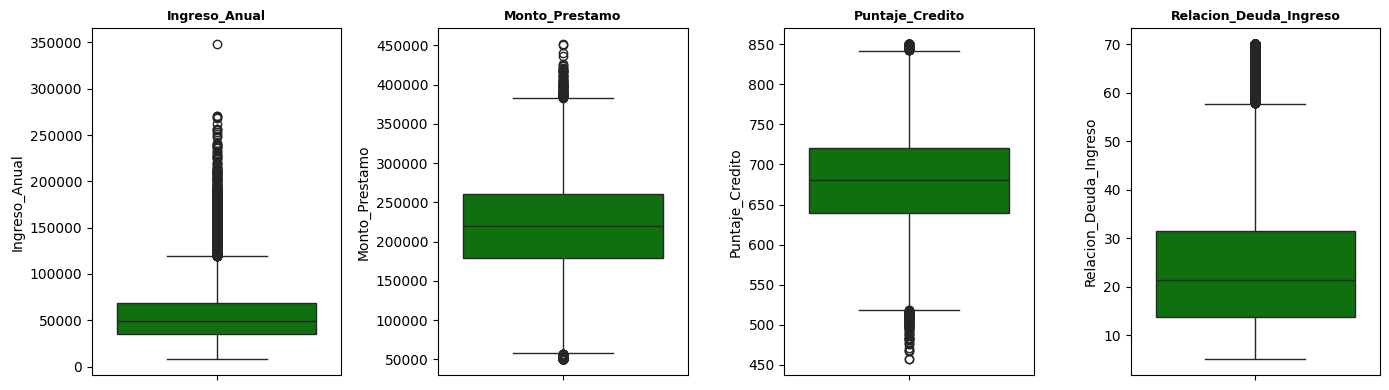

In [ ]:
variables = ["Ingreso_Anual", "Monto_Prestamo", "Puntaje_Credito", "Relacion_Deuda_Ingreso"]

# Cuenta los valores fuera de las cercas del rango intercuartílico
def contar_outliers(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum())

resumen_outliers = pd.DataFrame({
    "Outliers": {v: contar_outliers(data[v]) for v in variables},
    "Asimetria": data[variables].skew().round(2),
})
resumen_outliers["Porcentaje"] = (resumen_outliers["Outliers"] / len(data) * 100).round(2)
display(resumen_outliers)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, variable in zip(axes, variables):
    sns.boxplot(y=data[variable], ax=ax, color="green")
    ax.set_title(variable, fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()

Se encontró que las 4 variables presentan outliers:

Ingreso\_Anual es la variable que presenta mayor cantidad de valores atípicos \(3,9%\) y una asimetría positiva marcada \(1,7\)

Relación\_Deuda\_Ingreso también tiene asimetria a la derecha y un 2,65% de valores atípicos

Finalmente Monto\_Prestamo y Puntaje\_Credito tienen menos del 1% de los atípicos

Los outliers corresponden a valores posibles \(personas con ingresos altos o que se encuentran muy endeudadas\), por lo tanto no se eliminan\. En las variables monetarias aplicamos el winsorizer al 1% solo para limitar un poco los clientes atípicos

## Desbalance de la variable objetivo

,Clientes,Porcentaje
Riesgo_Impago,,
0,23211,92.84
1,1789,7.16


Razón de desbalance: 13.0 cumplidores por cada impago


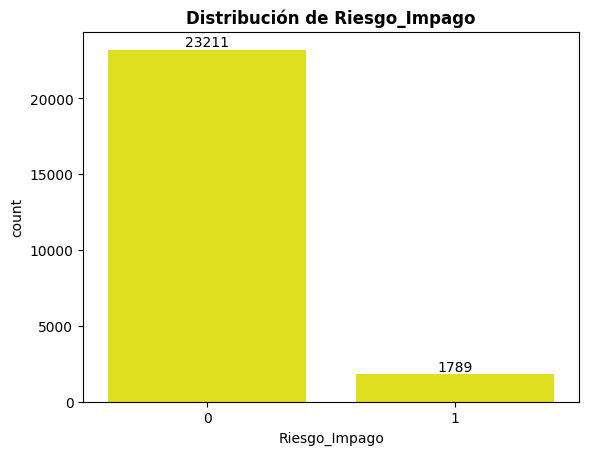

In [ ]:
conteo = data[target].value_counts()
proporcion = data[target].value_counts(normalize=True) * 100
display(pd.DataFrame({"Clientes": conteo, "Porcentaje": proporcion.round(2)}))
print(f"Razón de desbalance: {conteo[0] / conteo[1]:.1f} cumplidores por cada impago")

ax = sns.countplot(x=target, data=data, color="yellow")
ax.bar_label(ax.containers[0])
ax.set_title("Distribución de Riesgo_Impago", fontweight="bold")
plt.show()

La variable objetivo está fuertemente desbalanceada ya que el 92,84% de los clientes cumple y solo el 7,16% cae en impago, por lo tanto:

- La accuracy no sirve como métrica puesto que se obtendría un 92,8% de accuracy sin detectar ningún impago

- En la optimización se prueba con class\_weight = "balanced" para que el árbol de más peso a la clase minoritaria

## Relación de las variables con el impago

Puntaje_Credito          -0.1402
Ingreso_Anual            -0.1128
Monto_Prestamo            0.1213
Relacion_Deuda_Ingreso    0.3090
Name: Riesgo_Impago, dtype: float64
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will

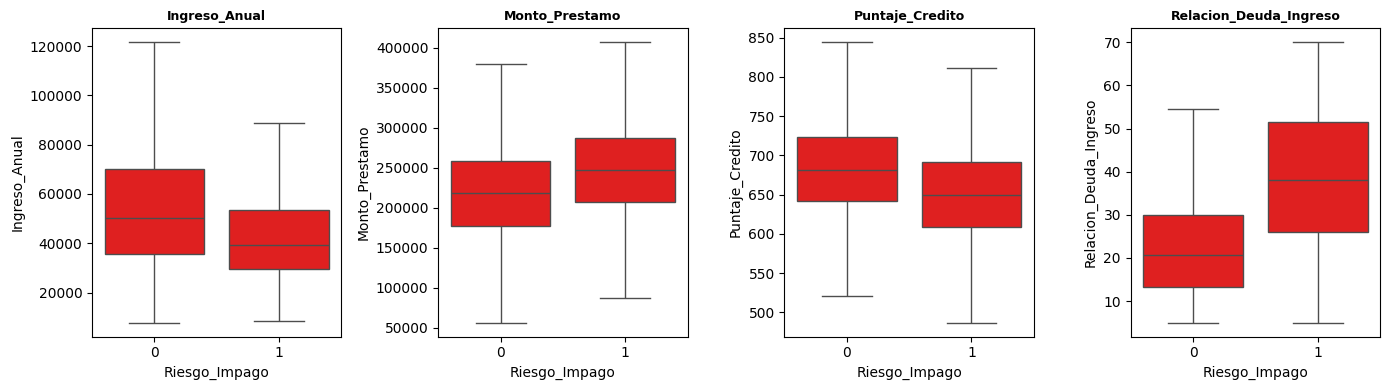

In [ ]:
correlaciones = data.corr(numeric_only=True)[target].drop(target).sort_values()
print(correlaciones.round(4))

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, variable in zip(axes, variables):
    sns.boxplot(data=data, x=target, y=variable, ax=ax, color="red", showfliers=False)
    ax.set_title(variable, fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()

Se aprecia que el ingreso anual, el monto del préstamo y el puntaje crediticio poco tienen que ver con que el cliente pague o no el préstamo, por otra parte la relación deuda ingreso sí influye en mayor medida\. Las boxplot de las tres primeras variables demuestran que los clientes se mezclan mucho entre quienes pagan y no\.

La única variable que presenta está diferencia ente los clientes es la relación deuda ingreso, donde los clientes no se mezclan tanto entre quienes pagarían su deuda y quienes no lo harán\.

# Fase 2: Limpieza y tratamiento de datos

## Transformadores personalizados

In [ ]:
class FeatureEngineering(BaseEstimator, TransformerMixin):
    # Sin aprendizaje: la variable se calcula fila a fila
    def fit(self, X, y=None):
        return self

    # Invalida montos no positivos y agrega el ratio préstamo/ingreso
    def transform(self, X):
        X = X.copy()
        X["Ingreso_Anual"] = X["Ingreso_Anual"].where(X["Ingreso_Anual"] > 0)
        X["Monto_Prestamo"] = X["Monto_Prestamo"].where(X["Monto_Prestamo"] > 0)
        X["Ratio_Prestamo_Ingreso"] = X["Monto_Prestamo"] / X["Ingreso_Anual"]
        return X


class Winsorizer(BaseEstimator, TransformerMixin):
    # Guarda los límites de cada variable
    def __init__(self, limits=(0.01, 0.01)):
        self.limits = limits

    # Aprende los percentiles solo con los datos de entrenamiento
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.columns_ = X.columns
        self.lower_ = X.quantile(self.limits[0])
        self.upper_ = X.quantile(1 - self.limits[1])
        return self

    # Recorta los valores extremos
    def transform(self, X):
        X = pd.DataFrame(X, columns=self.columns_).astype("float64")
        return X.clip(lower=self.lower_, upper=self.upper_, axis=1)

    # Entrega los nombres de salida
    def get_feature_names_out(self, input_features=None):
        return np.array(self.columns_, dtype=object)

- FeatureEngineering crea la variable Ratio\_Prestamo\_Ingreso \(monto solicitado/ ingreso actual\), y lo que mide es cuantos años de ingreso representa la hipoteca, ademas convierte en nulos los montos o ingresos no positivos para que luego el imputador los trate

- Winsorizer recorta los valores bajo el percentil 1 y sobre el percentil 99\. Los limites se aprenden solo con los datos de entrenamiento y luego se aplican al conjunto de prueba para así evitar la fuga de información \(data leakage\)

## Pipeline de preprocesamiento

In [ ]:
outlier_features = ["Ingreso_Anual", "Monto_Prestamo", "Ratio_Prestamo_Ingreso"]
num_features = ["Puntaje_Credito", "Relacion_Deuda_Ingreso"]

outlier_transformer = Pipeline(steps=[
    ("winsorizer", Winsorizer(limits=(0.01, 0.01))),
    ("imputer", SimpleImputer(strategy="median")),
])

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])

columnas = ColumnTransformer(transformers=[
    ("outliers", outlier_transformer, outlier_features),
    ("num", numeric_transformer, num_features),
], verbose_feature_names_out=False).set_output(transform="pandas")

X = data.drop(columns=[target])
y = data[target]
print(f"Dimensiones de X: {X.shape} | Dimensiones de y: {y.shape}")

Dimensiones de X: (25000, 4) | Dimensiones de y: (25000,)


A las variables monetarias con colas largas \(Ingreso\_Anual, Monto\_Prestamo, Ratio\_Prestamo\_Ingreso\) se les aplica el winsorizer al 1% además de la imputación por la mediana, a las variables que ya se encuentran acotadas \(Puntaje\_Credito, Relacion\_Deuda\_Ingreso\) solo la imputación

No se estandariza porque los arboles de decisión no dependen de la escala de las variables

# Fase 3: Construcción del Modelo

## División entre train y test

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print(f"Train: {X_train.shape[0]} | tasa de impago: {y_train.mean():.2%}")
print(f"Test:  {X_test.shape[0]} | tasa de impago: {y_test.mean():.2%}")

Train: 20000 | tasa de impago: 7.16%
Test:  5000 | tasa de impago: 7.16%


Se divide 80/20 eso quiere decir que utilizaremos el 80% de los datos para entrenamiento y el 20% restante se reserva para las pruebas

## Modelo de línea base \(datos sin balancear\)

Árbol con los hiperparámetros por defecto: sin limite de profundidad y sin balancear las clases

In [ ]:
baseline_tree = Pipeline(steps=[
    ("feature_engineering", FeatureEngineering()),
    ("columnas", clone(columnas)),
    ("modelo", DecisionTreeClassifier(random_state=SEED)),
])
baseline_tree.fit(X_train, y_train)

# Predicciones
y_pred_base = baseline_tree.predict(X_test)
y_proba_base = baseline_tree.predict_proba(X_test)[:, 1]

# Comprueba la existencia de overfitting
print(f"PR-AUC Línea Base: {average_precision_score(y_test, y_proba_base):.4f}")
print("=" * 100)
print(f"Recall (impago) línea base en train: {recall_score(y_train, baseline_tree.predict(X_train)):.4f}")
print(f"Recall (impago) línea base en test: {recall_score(y_test, y_pred_base):.4f}")

PR-AUC Línea Base: 0.1544
Recall (impago) línea base en train: 1.0000
Recall (impago) línea base en test: 0.3603


La linea base presenta un claro overfitting:

- En el train se tiene un recall perfecto de 1 pero en la prueba solo se detecta el 36% de los impagos, al no tener limite de profundidad el árbol memoriza los datos de entrenamiento y no generaliza

- El PR\-AUC es de 0,154

## Matriz de confusión de la línea base

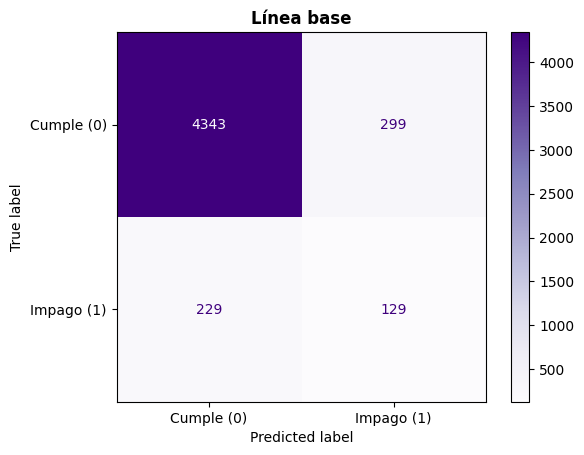

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_base, display_labels=["Cumple (0)", "Impago (1)"], cmap="Purples"
)
plt.title("Línea base", fontweight="bold")
plt.show()

## Optimización del árbol

In [ ]:
pipe_opt = Pipeline(steps=[
    ("feature_engineering", FeatureEngineering()),
    ("columnas", clone(columnas)),
    ("modelo", DecisionTreeClassifier(random_state=SEED)),
])

param_grid = {
    "modelo__criterion": ["gini", "entropy"],
    "modelo__max_depth": [3, 4, 5, 6, 8],
    "modelo__min_samples_split": [5, 10, 20],
    "modelo__min_samples_leaf": [2, 5, 10],
    "modelo__class_weight": [None, "balanced"],
}

grid_search = GridSearchCV(
    estimator= pipe_opt,
    param_grid = param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    scoring="average_precision",
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

mejor_arbol = grid_search.best_estimator_
mejor_criterio = grid_search.best_params_["modelo__criterion"]
target_names = ["Cumple", "Impago"]

**Pipeline completo dentro del GridSearch.** Se incluyen `FeatureEngineering` y el preprocesamiento (winsorizer + imputación) dentro del pipeline, de modo que en cada fold de la validación cruzada los límites del winsorizer y las medianas se aprenden solo con los datos de entrenamiento de ese fold. Así se evita la fuga de información (data leakage) hacia los datos de validación.

**Hiperparámetros explorados** (2 × 5 × 3 × 3 × 2 = 180 combinaciones):
- `criterion` (gini, entropy): son dos medidas de impureza para elegir las divisiones. No hay una mejor a priori, por lo que se deja que la validación cruzada decida.
- `max_depth` (3 a 8): limita la profundidad para controlar el sobreajuste. La línea base, sin límite, obtuvo un recall de 1,0 en train frente a 0,36 en test, lo que muestra que memorizaba los datos. Una profundidad moderada además mantiene el árbol interpretable para el negocio.
- `min_samples_split` y `min_samples_leaf`: exigen un mínimo de registros para dividir un nodo y para formar una hoja. Se usan valores bajos o moderados porque la clase impago es minoritaria (7,16%), y hojas muy grandes diluirían los pocos casos de impago.
- `class_weight` (None, balanced): compara el árbol sin compensar contra uno que pondera cada clase de forma inversa a su frecuencia. Con "balanced", equivocarse con un impago pesa más, lo que va en línea con que un falso negativo cuesta $1.500.000 frente a $200.000 de un falso positivo.

**Validación cruzada.** Se usa `StratifiedKFold` con 5 folds para mantener la proporción de impagos (~7%) en cada partición. Con una división simple podría quedar un fold con muy pocos impagos y la métrica sería inestable. `shuffle=True` evita depender del orden de los datos y `random_state=SEED` hace que los resultados sean reproducibles (seed = 29). Se eligen 5 folds como equilibrio entre una estimación estable y un costo computacional razonable (180 × 5 = 900 entrenamientos).

**Métrica de selección: PR-AUC.** Evalúa para todos los umbrales, qué tan bien detecta el árbol los impagos (recall) sin generar demasiados rechazos de clientes buenos (precision). Se prefiere sobre ROC-AUC porque, con datos desbalanceados, ROC-AUC entrega una visión demasiado optimista: su eje de falsos positivos divide por todos los clientes cumplidores (la gran mayoría), por lo que cientos de rechazos indebidos apenas se notan. Los costos de negocio no se incluyen en la selección y se evalúan en la Fase 4.

**Resultado.** `best_estimator_` es el pipeline reentrenado con todo el conjunto de entrenamiento usando la mejor combinación encontrada.

In [ ]:
# Predicciones del modelo optimizado sobre el conjunto de prueba
y_pred_opt = mejor_arbol.predict(X_test)
y_proba_opt = mejor_arbol.predict_proba(X_test)[:, 1]

Se generan las predicciones del modelo optimizado sobre el conjunto de test, que no participó en el entrenamiento ni en la selección de hiperparámetros, por lo que la evaluación es imparcial.
- `predict` entrega la clase asignada (0 = cumple, 1 = impago), usada para las matrices de confusión, el recall y los costos.
- `predict_proba[:, 1]` entrega la probabilidad estimada de impago, necesaria para calcular el PR-AUC y dibujar la curva Precision-Recall

Se calculan los mismos valores que para la línea base, de modo que la comparación entre ambos modelos sea justa.

In [ ]:
pr_auc_base = average_precision_score(y_test, y_proba_base)
pr_auc_opt = average_precision_score(y_test, y_proba_opt)

print("--- HIPERPARÁMETROS ÓPTIMOS ENCONTRADOS ---")
print(grid_search.best_params_)
print("\n" + "=" * 50)
print(f"PR-AUC Línea Base: {pr_auc_base:.4f}")
print(f"PR-AUC Optimizado: {pr_auc_opt:.4f}")
print(f"Recall (impago) optimizado en train: {recall_score(y_train, mejor_arbol.predict(X_train)):.4f}")
print(f"Recall (impago) optimizado en test: {recall_score(y_test, y_pred_opt):.4f}")
print("=" * 50)

print("\n--- REPORTE DE CLASIFICACIÓN (LÍNEA BASE) ---")
print(classification_report(y_test, y_pred_base, target_names=target_names))

print("--- REPORTE DE CLASIFICACIÓN (MODELO OPTIMIZADO) ---")
print(classification_report(y_test, y_pred_opt, target_names=target_names))

--- HIPERPARÁMETROS ÓPTIMOS ENCONTRADOS ---
{'modelo__class_weight': 'balanced', 'modelo__criterion': 'entropy', 'modelo__max_depth': 6, 'modelo__min_samples_leaf': 5, 'modelo__min_samples_split': 20}

PR-AUC Línea Base: 0.1544
PR-AUC Optimizado: 0.3858
Recall (impago) optimizado en train: 0.7407
Recall (impago) optimizado en test: 0.7207

--- REPORTE DE CLASIFICACIÓN (LÍNEA BASE) ---
              precision    recall  f1-score   support

      Cumple       0.95      0.94      0.94      4642
      Impago       0.30      0.36      0.33       358

    accuracy                           0.89      5000
   macro avg       0.63      0.65      0.64      5000
weighted avg       0.90      0.89      0.90      5000

--- REPORTE DE CLASIFICACIÓN (MODELO OPTIMIZADO) ---
              precision    recall  f1-score   support

      Cumple       0.97      0.80      0.88      4642
      Impago       0.22      0.72      0.33       358

    accuracy                           0.79      5000
   macro avg  

El mejor árbol usa el criterio entropy, una profundidad máxima de 6 niveles, exige al menos 5 clientes en cada hoja, al menos 20 clientes para dividir un nodo, y da más peso a la clase minoritaria \(impago\) para compensar el desbalance\. Al limitar la profundidad y exigir un mínimo de clientes por hoja el arbol aprende reglas generales en vez de memorizar, el balanceo de clases hace que el árbol penalice más la omisión de un impago, lo que coincide perfecto con la realidad de un banco donde un falso negativo cuesta mucha más que un falso positivo

El recall en train es de 0,74 y en test de 0,72, son valores similares y eso quiere decir que el modelo ya no esta memorizando como hacia antes

# Fase 4: Evaluación e interpretación de métricas

## Métricas sobre el conjunto de prueba

In [ ]:
# Resume el desempeño y el costo de negocio de un modelo
def evaluar(y_real, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    return {
        "Recall": recall_score(y_real, y_pred),
        "PR-AUC": average_precision_score(y_real, y_proba),
        "VN": tn, "FP": fp, "FN": fn, "VP": tp,
        "Costo FP": fp * COSTO_FP,
        "Costo FN": fn * COSTO_FN,
        "Costo total": fp * COSTO_FP + fn * COSTO_FN,
    }

resultados = pd.DataFrame({
    "Línea base": evaluar(y_test, y_pred_base, y_proba_base),
    f"Optimizado ({mejor_criterio})": evaluar(y_test, y_pred_opt, y_proba_opt),
}).T
display(resultados.drop(columns=["VN", "FP", "FN", "VP"]))

,Recall,PR-AUC,Costo FP,Costo FN,Costo total
Línea base,0.360335,0.154406,59800000.0,343500000.0,403300000.0
Optimizado (entropy),0.720670,0.385839,186200000.0,150000000.0,336200000.0


Decidimos utilizar la métrica recall debido a que en este caso los falsos negativos salen muy costosos \($1\.500\.000\) a comparación de los falsos positivos

A modo de resumen, y para aterrizar los resultados del modelo optimizado, obtenemos la tabla anterior\.

El modelo de línea base no es tomado en consideración, pero lo usaremos para notar una mejoría incluso en los resultados económicos respecto al árbol optimizado\. Al rededor de $70 millones se podría ahorrar la institución financiera considerando los resultados generales de detección errónea de clientes\.

## Matrices de confusión

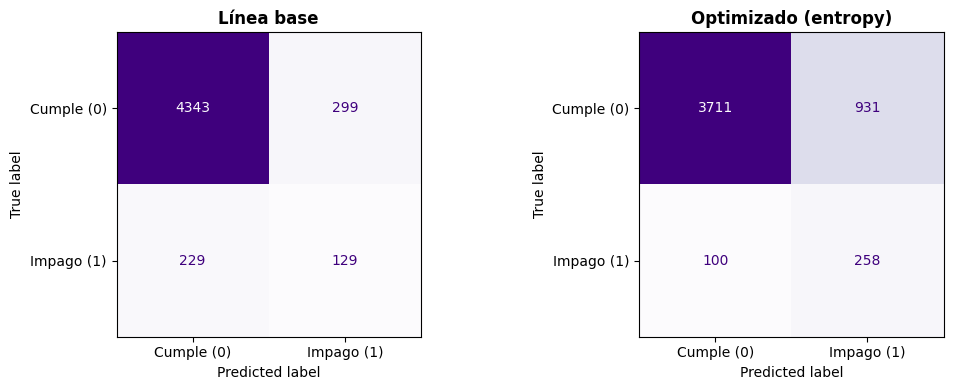

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
predicciones = {"Línea base": y_pred_base, f"Optimizado ({mejor_criterio})": y_pred_opt}
for ax, (nombre, y_pred) in zip(axes, predicciones.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["Cumple (0)", "Impago (1)"],
        cmap="Purples", ax=ax, colorbar=False,
    )
    ax.set_title(nombre, fontweight="bold")
plt.tight_layout()
plt.show()

Las comparación de las matrices de confusión del árbol base y el optimizado muestra que el opmitizado se vuelve más estricto al dar más peso a la clase impago\. El modelo pasó a ser más estricto a la hora de otorgar créditos a clientes\. Prefiere dar menos créditos a gente que lo puede pagar con tal de no prestar dinero a quien no va a pagar\. Cabe resaltar que los clientes que no pagarán son 7,5 veces más caros para la institución que uno que sí pagaría\.

# Comparativa ROC\-AUC y PR\-AUC

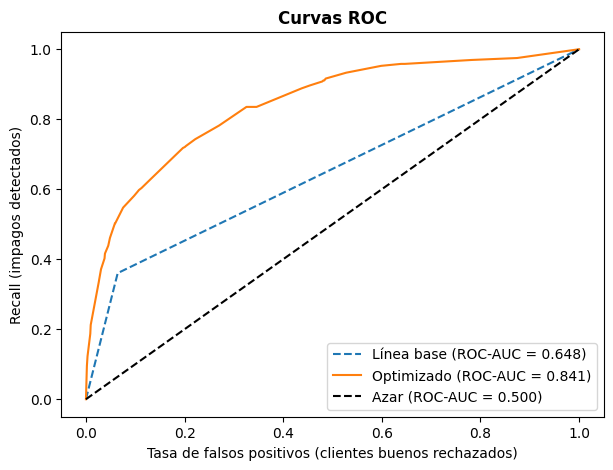

In [ ]:
from sklearn.metrics import roc_curve

# Curva ROC: compara el recall con la tasa de falsos positivos
fpr_base, tpr_base, _ = roc_curve(y_test, y_proba_base)
fpr_opt, tpr_opt, _ = roc_curve(y_test, y_proba_opt)

# ROC-AUC de cada modelo
roc_auc_base = roc_auc_score(y_test, y_proba_base)
roc_auc_opt = roc_auc_score(y_test, y_proba_opt)

plt.figure(figsize=(7, 5))
plt.plot(fpr_base, tpr_base, "--", label=f"Línea base (ROC-AUC = {roc_auc_base:.3f})")
plt.plot(fpr_opt, tpr_opt, label=f"Optimizado (ROC-AUC = {roc_auc_opt:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar (ROC-AUC = 0.500)")
plt.xlabel("Tasa de falsos positivos (clientes buenos rechazados)")
plt.ylabel("Recall (impagos detectados)")
plt.title("Curvas ROC", fontweight="bold")
plt.legend(loc="lower right")
plt.show()

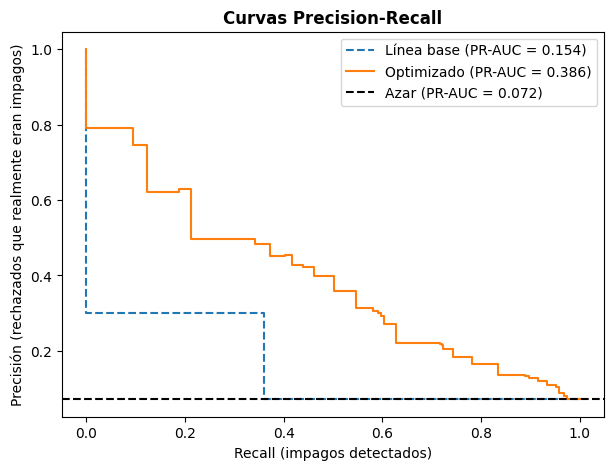

,ROC-AUC,PR-AUC
Línea base,0.648,0.154
Optimizado (entropy),0.841,0.386
Azar,0.500,0.072


In [ ]:
# Curva Precision-Recall: se enfoca solo en la clase positiva (Impago = 1)
prec_base, rec_base, _ = precision_recall_curve(y_test, y_proba_base)
prec_opt, rec_opt, _ = precision_recall_curve(y_test, y_proba_opt)

# PR-AUC (average precision) de cada modelo
pr_auc_base = average_precision_score(y_test, y_proba_base)
pr_auc_opt = average_precision_score(y_test, y_proba_opt)

# Un clasificador al azar obtiene una precisión igual a la tasa de impago
tasa_impago = y_test.mean()

plt.figure(figsize=(7, 5))
plt.step(rec_base, prec_base, "--", where="post", label=f"Línea base (PR-AUC = {pr_auc_base:.3f})")
plt.step(rec_opt, prec_opt, where="post", label=f"Optimizado (PR-AUC = {pr_auc_opt:.3f})")
plt.axhline(tasa_impago, color="k", linestyle="--", label=f"Azar (PR-AUC = {tasa_impago:.3f})")
plt.xlabel("Recall (impagos detectados)")
plt.ylabel("Precisión (rechazados que realmente eran impagos)")
plt.title("Curvas Precision-Recall", fontweight="bold")
plt.legend(loc="upper right")
plt.show()

# Comparación directa entre ambas métricas
display(pd.DataFrame({
    "ROC-AUC": [roc_auc_score(y_test, y_proba_base), roc_auc_score(y_test, y_proba_opt), 0.5],
    "PR-AUC": [pr_auc_base, pr_auc_opt, tasa_impago],
}, index=["Línea base", f"Optimizado ({mejor_criterio})", "Azar"]).round(3))

Ambas curvas responden a preguntas diferentes\. La institución financiera busca detectar impagos, es decir, una minoría o una anomalía, por lo cual la PR\-AUC representa mejor lo que se está buscando con el modelo\.

La curva ROC se presenta como referencia, el valor del modelo optimizado alcanza 0,841 lo que señala una buena capacidad de ordenar a los clientes que pagan y a los que no, sin embargo esta métrica no contempla el desbalance de los datos\.

La curva PR no tiene un valor deseable como tal, más bien depende de la relación con el valor PR del azar\. Por ejemplo si la institución utiliza el modelo entrenado para detectar clientes que no pagarán, el modelo rendirá 5,36 veces mejor que el azar \(0,386 / 0,072\)\. ¿A qué se refiere lo anterior? Si tomamos 358 impagos de los 5000 clientes tenemos el 7,2%, usando ese porcentaje como azar \(por la misma proporción natural de los datos\) cada 100 clientes que 7 serán impagos\. En cambio, el valor PR\-AUC corresponde a 39%, lo que es equivalente a decir que cerca de 39 de cada 100 impagos son rechazados reales\.

## Interpretación financiera de las matrices

In [ ]:
# Traduce una fila de resultados al lenguaje del negocio
def interpretar(nombre, fila):
    total_impagos = fila["VP"] + fila["FN"]
    print(f"--- {nombre} ---")
    print(f"VP: {fila['VP']:.0f} impagos detectados de {total_impagos:.0f} ({fila['VP'] / total_impagos:.1%}): crédito no otorgado y capital protegido.")
    print(f"FN: {fila['FN']:.0f} impagos aprobados por error: ${fila['Costo FN']:,.0f} en pérdida directa.")
    print(f"FP: {fila['FP']:.0f} clientes viables rechazados: ${fila['Costo FP']:,.0f} en intereses no percibidos.")
    print(f"VN: {fila['VN']:.0f} clientes cumplidores aprobados correctamente.")
    print(f"Costo total: ${fila['Costo total']:,.0f}\n")

for nombre, fila in resultados.iterrows():
    interpretar(nombre, fila)

ahorro = resultados["Costo total"].iloc[0] - resultados["Costo total"].iloc[1]
print(f"Ahorro del modelo optimizado en el conjunto de prueba: ${ahorro:,.0f}")

--- Línea base ---
VP: 129 impagos detectados de 358 (36.0%): crédito no otorgado y capital protegido.
FN: 229 impagos aprobados por error: $343,500,000 en pérdida directa.
FP: 299 clientes viables rechazados: $59,800,000 en intereses no percibidos.
VN: 4343 clientes cumplidores aprobados correctamente.
Costo total: $403,300,000

--- Optimizado (entropy) ---
VP: 258 impagos detectados de 358 (72.1%): crédito no otorgado y capital protegido.
FN: 100 impagos aprobados por error: $150,000,000 en pérdida directa.
FP: 931 clientes viables rechazados: $186,200,000 en intereses no percibidos.
VN: 3711 clientes cumplidores aprobados correctamente.
Costo total: $336,200,000

Ahorro del modelo optimizado en el conjunto de prueba: $67,100,000


**Por qué se traduce la matriz a dinero.** Las métricas como el recall dicen cuántos impagos se detectan, pero no cuánto vale equivocarse. Como un impago aprobado cuesta 1.500.000 y un cliente bueno rechazado cuesta 200.000, cada tipo de error pesa distinto. Esta sección convierte cada casilla de la matriz en su costo para comparar los modelos con el criterio del negocio.

**Línea base**
- Detecta 129 de los 358 impagos (36,0%) y protege ese capital.
- Deja pasar **229 impagos**, que generan una pérdida directa de **343,5 millones**.
- Rechaza a 299 clientes viables, con un costo de **59,8 millones** en intereses no percibidos.
- Costo total: **403,3 millones**, de los cuales el 85% corresponde a impagos no detectados.

**Modelo optimizado (entropy)**
- Detecta 258 de los 358 impagos (72,1%), el doble que la línea base.
- Solo **100 impagos** se le escapan, con una pérdida de **150 millones**.
- Rechaza a 931 clientes viables, con un costo de **186,2 millones**.
- Costo total: **336,2 millones**.

**Comparación.** Frente a la línea base, el modelo optimizado evita 129 impagos (ahorra 193,5 millones) pero rechaza 632 clientes buenos más (cuesta 126,4 millones). El resultado neto es un **ahorro de 67,1 millones en el conjunto de prueba, un 16,6% del costo de la línea base**.

**Por qué conviene aunque rechace más clientes.** Un impago evitado vale lo mismo que 7,5 rechazos de clientes buenos. El modelo optimizado "paga" unos 4,9 rechazos por cada impago que evita, por debajo de ese punto de equilibrio, y por eso el balance es favorable. Además, el costo se reparte de forma más pareja: los impagos no detectados pasan de ser el 85% del costo a ser el 45%.

## Variables más importantes del árbol optimizado

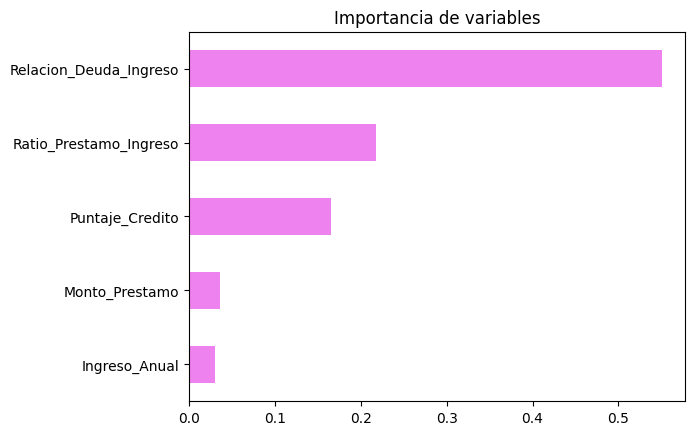

Relacion_Deuda_Ingreso    0.550
Ratio_Prestamo_Ingreso    0.218
Puntaje_Credito           0.166
Monto_Prestamo            0.036
Ingreso_Anual             0.030
dtype: float64

In [ ]:
importancias = pd.Series(
    mejor_arbol.named_steps["modelo"].feature_importances_,
    index=mejor_arbol.named_steps["columnas"].get_feature_names_out(),
).sort_values()

importancias.plot.barh(color="violet", title="Importancia de variables")
plt.show()
importancias.sort_values(ascending=False).round(3)

**Qué muestra este gráfico.** La importancia de una variable indica cuánto contribuye al árbol para separar a los clientes que pagan de los que no. Se calcula sumando cuánto reduce la impureza cada división que usa esa variable. Las cinco importancias suman 1, por lo que cada valor se lee como el porcentaje del "trabajo" del modelo que le corresponde a esa variable.

| Variable | Importancia |
|---|---|
| Relacion_Deuda_Ingreso | 0,550 |
| Ratio_Prestamo_Ingreso | 0,218 |
| Puntaje_Credito | 0,166 |
| Monto_Prestamo | 0,036 |
| Ingreso_Anual | 0,030 |

**Lectura para el negocio**
- **El endeudamiento domina.** `Relacion_Deuda_Ingreso` explica el 55% de las decisiones del árbol. Esto coincide con el análisis exploratorio: fue la variable más correlacionada con el impago (0,31) y la tasa de impago pasaba del 1,9% al 50% al subir el endeudamiento. Para el banco, el nivel de endeudamiento actual del cliente es la primera señal de alerta.
- **La variable creada aporta valor.** `Ratio_Prestamo_Ingreso` (monto solicitado dividido por el ingreso anual) es la segunda en importancia, con un 21,8%. Mide cuántos años de ingreso representa el préstamo, y justifica haberla construida en la fase de limpieza.
- **El puntaje de crédito es la tercera señal** (16,6%). El historial previo del cliente suma información, pero pesa mucho menos que el endeudamiento actual.
- **Monto e ingreso por separado casi no importan** (3,6% y 3,0%). Lo relevante es la relación entre ambos y no cada uno por sí solo: un préstamo grande no es riesgoso si el ingreso es alto, y un ingreso bajo no lo es si el préstamo es pequeño.

## Primeros niveles del árbol

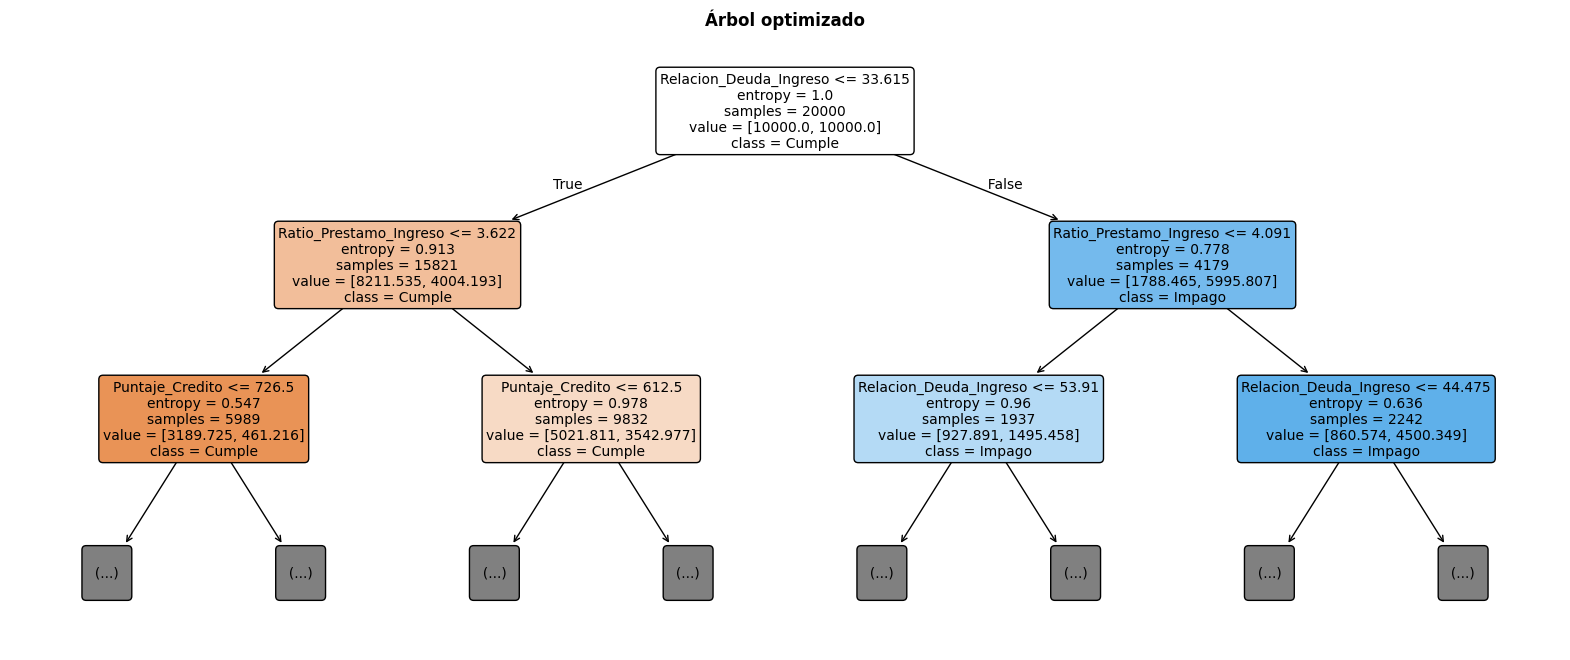

In [ ]:
plt.figure(figsize=(20, 8))
plot_tree(
    mejor_arbol.named_steps["modelo"],
    feature_names=mejor_arbol.named_steps["columnas"].get_feature_names_out(),
    class_names=target_names,
    max_depth=2, filled=True, rounded=True, fontsize=10,
)
plt.title("Árbol optimizado", fontweight="bold")
plt.show()

A considerar: Al inicio de cada recuadro se establece la regla de división para repartirse en los nodos hijos, Entropy nos dice que tan mezcladas están las clases un 1 es una mezcla de 50/50\. El value muestra la cantidad ponderada clientes de cada clase en el nodo \(Cumple, Impago\) y por ultimo "class" nos dice la clase que predeciera si el arbol se detuviera en tal nodo \(gana la clase con mas peso en value\)\.

**Primera pregunta: ¿el endeudamiento supera el 33,6% del ingreso?**
Es la variable más importante del árbol (55%) y confirma el análisis exploratorio.

| Grupo | Clientes | Impago real |
|---|---|---|
| DTI ≤ 33,6% | 15.821 | 3,6% |
| DTI > 33,6% | 4.179 | 20,5% |

Con solo esta pregunta, el grupo muy endeudado tiene un riesgo casi 6 veces mayor.

**Segunda pregunta: ¿el préstamo es grande en relación al ingreso?**
Usa `Ratio_Prestamo_Ingreso` (monto solicitado dividido por el ingreso anual), con corte en 3,6 veces el ingreso para quienes tienen poca deuda y 4,1 veces para los muy endeudados. Esto da cuatro grupos:

| Grupo | Clientes | Impago real | Clase |
|---|---|---|---|
| Poca deuda y préstamo moderado | 5.989 | 1,1% | Cumple |
| Poca deuda y préstamo grande | 9.832 | 5,2% | Cumple |
| Mucha deuda y préstamo moderado | 1.937 | 11,0% | Impago |
| Mucha deuda y préstamo grande | 2.242 | 28,7% | Impago |

El riesgo va de 1,1% a 28,7% con solo dos preguntas.

**Tercer nivel.** Después el árbol refina con el puntaje de crédito (cortes en 726 y 612 puntos) en los grupos con poca deuda, y con el endeudamiento (cortes en 44,5% y 53,9%) en los muy endeudados.

**Qué significa para el negocio**
- **El perfil de más riesgo** combina endeudamiento sobre 33,6% y un préstamo de más de 4 veces el ingreso anual: casi 3 de cada 10 clientes de ese grupo no pagan.
- **El perfil de menos riesgo** combina poca deuda y préstamo moderado: solo 1 de cada 100 no paga. El puntaje de crédito sirve después para afinar dentro de este grupo.
- **Las reglas se pueden explicar** con frases del tipo "mucha deuda y un préstamo grande en relación al ingreso", que es una ventaja de un árbol frente a modelos que no se pueden interpretar.
- **Es coherente con el resto del análisis:** las variables que usa en las primeras divisiones (endeudamiento, ratio préstamo/ingreso y puntaje) son las tres más importantes del gráfico anterior.

**Por qué el árbol marca como Impago grupos de riesgo moderado.** Con el balanceo de clases, un grupo se clasifica como Impago si su tasa real de impago supera aproximadamente el 7%, que es la tasa general de la base. Por eso el grupo con 11% de impago aparece en azul aunque 9 de cada 10 de sus clientes sí paguen. Es una decisión consistente con que un impago cuesta mucho más que un rechazo, y explica por qué el modelo rechaza a más clientes buenos (931) que la línea base.
